In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString
from scipy.stats import spearmanr

In [17]:
# read 2010, 2020 datasets
df10 = pd.read_csv("Amazon_Curvature_Width_Yearly - Amazon_Curvature_Width_2010.csv")
df20 = pd.read_csv("Amazon_Curvature_Width_Yearly - Amazon_Curvature_Width_Yearly2020.csv")

# sort
df10 = df10.sort_values("Index").reset_index(drop=True)
df20 = df20.sort_values("Index").reset_index(drop=True)

# wavelength coordinates: (start point, end point)
pairs = [(36, 107), (69, 141), (107, 172), (141, 202), (172, 248)] # found by hand

# get (E,N) of each point
coords10 = df10[["Easting", "Northing"]].to_numpy()
coords20 = df20[["Easting", "Northing"]].to_numpy()

# turn 2010 points into a continuous centerline 
line10 = LineString(coords10)

displacements = []

# calculate 2010-2020 displacement
for i in range(1, len(df20) - 1):
    p = coords20[i]
    tangent = coords20[i + 1] - coords20[i - 1]
    normal = np.array([-tangent[1], tangent[0]])
    normal = normal / np.linalg.norm(normal)

    width = df20.loc[i, "Width"]
    transect = LineString([p - 5 * width * normal, p + 5 * width * normal])
    intersection = transect.intersection(line10)

    if intersection.geom_type == "Point":
        dx = Point(p).distance(intersection)
    else:
        dx = np.nan

    displacements.append(dx)

# add dx measurements into the DataFrame
df20["dx"] = [np.nan] + displacements + [np.nan]

In [15]:
df20["wavelength"] = 0.0
df20["count"] = 0

for start, end in pairs:
    p1 = df20[df20["Index"] == start].iloc[0]
    p2 = df20[df20["Index"] == end].iloc[0]

    wavelength = np.hypot(p2["Easting"] - p1["Easting"],p2["Northing"] - p1["Northing"])

    # select points with existing wavelength measurements
    mask = df20["Index"].between(start, end)
    df20.loc[mask, "wavelength"] += wavelength
    df20.loc[mask, "count"] += 1

# account for points that correspond to several wavelengths 
df20["wavelength"] = df20["wavelength"] / df20["count"]

# calculate nondimensional parameters
df20["lambda/W"] = df20["wavelength"] / df20["Width"]
df20["R/W"] = 1 / (df20["curvature"].abs() * df20["Width"])
df20["dx/W"] = df20["dx"] / df20["Width"]

# clean the dataFrame
data = df20.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["lambda/W", "R/W", "dx/W"])
data = data[data["curvature"].abs() > 1e-8]

print("Number of valid points:", len(data))
display(data[["Index", "lambda/W", "R/W", "dx/W"]].head())

Number of valid points: 79


,Index,lambda/W,R/W,dx/W
40,41,14.624785,0.982642,0.726843
41,42,11.427356,1.336305,0.475575
44,45,17.380794,3.716065,0.312334
45,46,17.676021,8.386191,0.576093
49,50,35.016400,47.922522,1.857032


R value for lambda/W constant: -0.17226890756302524
R value for R/W constant: 0.5000000000000001
R value for dx/W constant: 0.34545454545454546


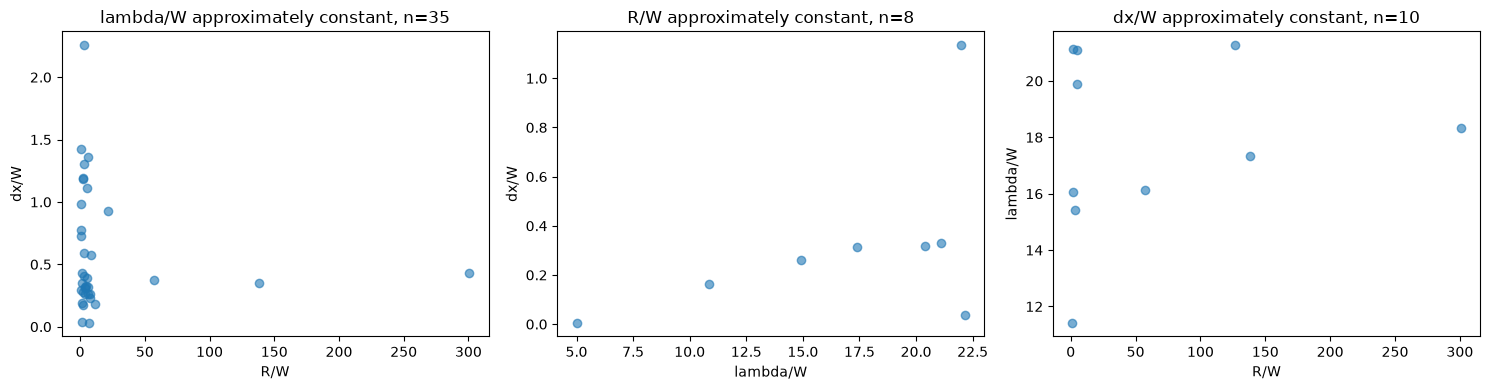

In [23]:
# dimensional analysis plots
variables = ["lambda/W", "R/W", "dx/W"]
tolerance = 0.2

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, fixed, x, y in zip(axes,variables,["R/W", "lambda/W", "R/W"], ["dx/W", "dx/W", "lambda/W"]):
    center = data[fixed].median()

    # keep the fixed variable in the given range
    subset = data[data[fixed].between(center * (1 - tolerance),center * (1 + tolerance))]

    ax.scatter(subset[x], subset[y], alpha=0.6)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{fixed} approximately constant, n={len(subset)}")

    print(f"R value for {fixed} constant:", spearmanr(subset[x], subset[y]).statistic)

plt.tight_layout()
plt.show()